# EcoVision AI — Clasificación inteligente de residuos con Deep Learning

**Proyecto final de Deep Learning para Visión**  
**Estado del cuaderno:** ejecutable, finalizado de entrenamiento y evaluación con datos reales.  

**Pregunta:** ¿Qué tan bien puede una red convolucional clasificar residuos a partir de fotografías y qué se gana con transferencia de aprendizaje?

**Objetivos**
1. Explorar un dataset público con seis categorías de residuos.
2. Entrenar una **CNN desde cero** y un **ResNet18 preentrenado**.
3. Comparar ambos modelos usando un conjunto de validación y un test separado.
4. Visualizar aciertos, errores, curvas y un mapa de atención Grad-CAM.
5. Guardar un modelo para su uso mediante Streamlit.

> **Importante:** los resultados se calculan al ejecutar este cuaderno; no se han supuesto métricas. El conjunto de prueba se mantiene separado hasta terminar el entrenamiento.

**Datos:** [Garbage Classification (Kaggle)](https://www.kaggle.com/datasets/asdasdasasdas/garbage-classification) — categorías `cardboard`, `glass`, `metal`, `paper`, `plastic`, `trash`. Consulta la licencia y la procedencia antes de cualquier distribución de imágenes.

## 0. Instalación y configuración

Ejecuta las celdas en orden. En Colab, selecciona **Entorno de ejecución > Cambiar tipo de entorno de ejecución > GPU**, si está disponible. También funciona con CPU, pero entrenará más lento.

La primera ejecución requiere conexión a Internet para descargar datos y pesos de ImageNet. Si trabajas desde una carpeta descargada, ejecútalo desde la carpeta que contiene este notebook.

In [1]:
%pip -q install kagglehub scikit-learn matplotlib seaborn pandas pillow

In [13]:
import copy
import hashlib
import json
import random
import time
from collections import Counter
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from PIL import Image, UnidentifiedImageError
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__, '| Dispositivo:', device)

# Usa True para hacer la primera ejecución rápidamente; pon False para el trabajo final.
MODO_RAPIDO = False
IMAGE_SIZE = 128 if MODO_RAPIDO else 160
BATCH_SIZE = 24 if device.type == 'cuda' else 16
EPOCHS_CNN = 4 if MODO_RAPIDO else 12
EPOCHS_RESNET = 3 if MODO_RAPIDO else 8
MAX_TRAIN_POR_CLASE = 140 if MODO_RAPIDO else None  # solo reduce ENTRENAMIENTO; val/test completos

ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(parents=True, exist_ok=True)

PyTorch: 2.14.1+cpu | Dispositivo: cpu


## 1. Descarga y exploración inicial de los datos

Se descarga el dataset público con `kagglehub`, se ubican automáticamente las seis subcarpetas de clases y se descartan archivos corruptos y copias **exactas** antes de separar los datos. No se asegura la eliminación de duplicados visuales con ligeras modificaciones; es una limitación del estudio.

In [14]:
DATASET_ID = 'asdasdasasdas/garbage-classification'
CLASES_ESPERADAS = {'cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash'}

ruta_descarga = Path(kagglehub.dataset_download(DATASET_ID))
print('Dataset descargado en:', ruta_descarga)

# Encuentra la carpeta que contenga directamente las seis clases, sin asumir estructura del ZIP.
carpetas = [ruta_descarga] + [p for p in ruta_descarga.rglob('*') if p.is_dir()]
candidatas = []
for folder in carpetas:
    subdirs = {p.name.lower() for p in folder.iterdir() if p.is_dir()}
    if CLASES_ESPERADAS.issubset(subdirs):
        candidatas.append(folder)
if not candidatas:
    raise FileNotFoundError('No encontré las 6 carpetas de TrashNet. Estructura: ' +
                            '\n'.join(str(p) for p in list(ruta_descarga.rglob('*'))[:30]))
DATA_DIR = min(candidatas, key=lambda p: len(p.parts))
clases = sorted(CLASES_ESPERADAS)
class_to_idx = {c: i for i, c in enumerate(clases)}
print('Directorio:', DATA_DIR)
print('Categorías:', clases)

ext_validas = {'.jpg', '.jpeg', '.png', '.webp', '.bmp'}
registros = []
hashes_vistos = set()
archivos_invalidos = 0
copias_exactas = 0
for clase in clases:
    carpeta = next(p for p in DATA_DIR.iterdir() if p.is_dir() and p.name.lower() == clase)
    for archivo in sorted(carpeta.rglob('*')):
        if not archivo.is_file() or archivo.suffix.lower() not in ext_validas:
            continue
        try:
            with Image.open(archivo) as im:
                im.verify()
            firma = hashlib.sha256(archivo.read_bytes()).hexdigest()
        except (OSError, UnidentifiedImageError, ValueError):
            archivos_invalidos += 1
            continue
        if firma in hashes_vistos:
            copias_exactas += 1
            continue
        hashes_vistos.add(firma)
        registros.append({'ruta': str(archivo), 'clase': clase, 'etiqueta': class_to_idx[clase]})

df = pd.DataFrame(registros)
if df.empty or df['clase'].nunique() != 6:
    raise RuntimeError('El dataset no tiene muestras válidas para las seis clases.')
print(f'Imágenes válidas: {len(df)} | Corruptas: {archivos_invalidos} | Duplicadas exactas: {copias_exactas}')
print(df['clase'].value_counts().sort_index().to_string())

Using Colab cache for faster access to the 'garbage-classification' dataset.
Dataset descargado en: /kaggle/input/garbage-classification
Directorio: /kaggle/input/garbage-classification/Garbage classification/Garbage classification
Categorías: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Imágenes válidas: 2524 | Corruptas: 0 | Duplicadas exactas: 3
clase
cardboard    403
glass        501
metal        409
paper        594
plastic      480
trash        137


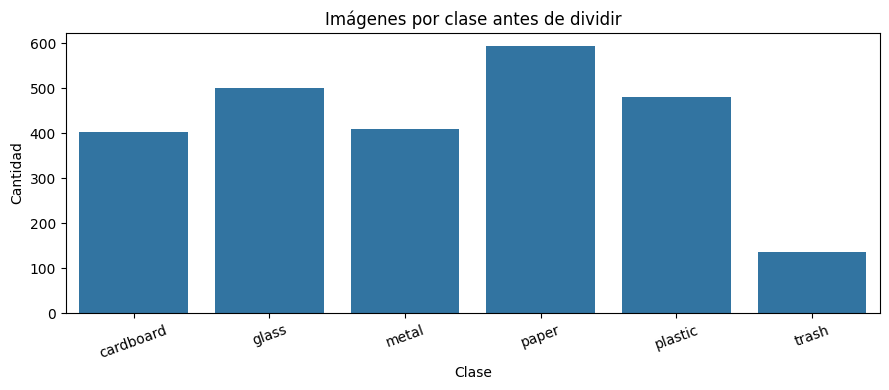

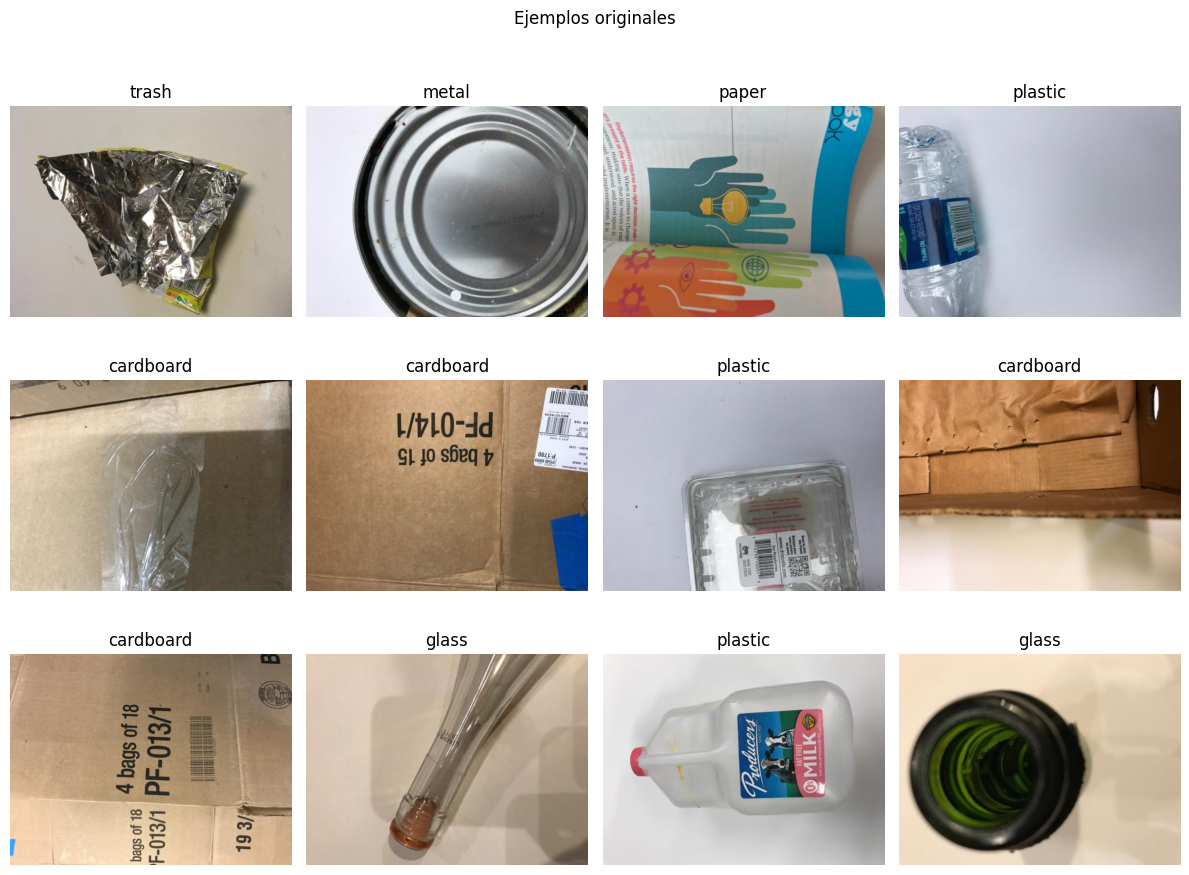

In [15]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.countplot(data=df, x='clase', order=clases, ax=ax)
ax.set(title='Imágenes por clase antes de dividir', xlabel='Clase', ylabel='Cantidad')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

muestra = df.sample(n=min(12, len(df)), random_state=SEED)
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax, (_, row) in zip(axes.flat, muestra.iterrows()):
    with Image.open(row['ruta']) as im:
        ax.imshow(im.convert('RGB'))
    ax.set_title(row['clase'])
    ax.axis('off')
for ax in axes.flat[len(muestra):]:
    ax.axis('off')
plt.suptitle('Ejemplos originales', y=1.01)
plt.tight_layout()
plt.show()

## 2. División estratificada y preprocesamiento

- **70 % entrenamiento**, **15 % validación**, **15 % prueba**.
- Los aumentos (`flip`, rotación y color) se aplican **únicamente a entrenamiento**.
- La selección del mejor modelo se hace con validación. El test no se usa para elegir hiperparámetros.
- En `MODO_RAPIDO`, solo se reduce el número de imágenes del entrenamiento para validar el flujo; para entregar resultados finales, cambiar a `False` y ejecutar todo nuevamente.

In [16]:
train_df, temp_df = train_test_split(df, test_size=0.30, random_state=SEED,
                                     stratify=df['etiqueta'])
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=SEED,
                                   stratify=temp_df['etiqueta'])
if MAX_TRAIN_POR_CLASE is not None:
    train_df = (train_df.groupby('clase', group_keys=False)
               .apply(lambda g: g.sample(n=min(len(g), MAX_TRAIN_POR_CLASE), random_state=SEED)))
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
assert not (set(train_df.ruta) & set(val_df.ruta))
assert not (set(train_df.ruta) & set(test_df.ruta))
assert not (set(val_df.ruta) & set(test_df.ruta))

print('Distribución por partición:')
print(pd.DataFrame({
    'train': train_df.clase.value_counts(),
    'val': val_df.clase.value_counts(),
    'test': test_df.clase.value_counts()
}).reindex(clases).fillna(0).astype(int))

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_tfms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(12),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.12),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])
val_tfms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

class ResiduosDataset(Dataset):
    def __init__(self, tabla, transform):
        self.tabla = tabla.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.tabla)
    def __getitem__(self, i):
        fila = self.tabla.iloc[i]
        with Image.open(fila['ruta']) as img:
            img = img.convert('RGB')
            x = self.transform(img)
        return x, int(fila['etiqueta'])

train_dl = DataLoader(ResiduosDataset(train_df, train_tfms), batch_size=BATCH_SIZE,
                      shuffle=True, num_workers=0)
val_dl = DataLoader(ResiduosDataset(val_df, val_tfms), batch_size=BATCH_SIZE,
                    shuffle=False, num_workers=0)
test_dl = DataLoader(ResiduosDataset(test_df, val_tfms), batch_size=BATCH_SIZE,
                     shuffle=False, num_workers=0)

Distribución por partición:
           train  val  test
clase                      
cardboard    282   61    60
glass        350   75    76
metal        286   62    61
paper        416   89    89
plastic      336   72    72
trash         96   20    21


## 3. Modelos que vamos a comparar

**Modelo A:** CNN pequeña entrenada desde cero.  
**Modelo B:** ResNet18 con pesos de ImageNet y su cuerpo congelado; entrenamos su capa final (**transfer learning**). Esta opción acelera el entrenamiento, pero no equivale a un fine-tuning de todas las capas.

Referencia: [tutorial de transferencia de aprendizaje PyTorch](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html).

In [17]:
class EcoCNN(nn.Module):
    def __init__(self, n_clases):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(64, 96), nn.ReLU(),
                                         nn.Dropout(0.35), nn.Linear(96, n_clases))
    def forward(self, x):
        return self.classifier(self.features(x))


def crear_modelo(nombre, n_clases, pesos_preentrenados=False):
    if nombre == 'cnn':
        return EcoCNN(n_clases)
    if nombre == 'resnet18':
        pesos = models.ResNet18_Weights.IMAGENET1K_V1 if pesos_preentrenados else None
        modelo = models.resnet18(weights=pesos)
        for p in modelo.parameters():
            p.requires_grad = False
        modelo.fc = nn.Sequential(nn.Dropout(0.25), nn.Linear(modelo.fc.in_features, n_clases))
        return modelo
    raise ValueError(f'Arquitectura no reconocida: {nombre}')

modelos = {
    'cnn': crear_modelo('cnn', len(clases)),
    'resnet18': crear_modelo('resnet18', len(clases), pesos_preentrenados=True),
}
for nombre, modelo in modelos.items():
    n_total = sum(p.numel() for p in modelo.parameters())
    n_entrenables = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
    print(f'{nombre}: parámetros totales={n_total:,}; entrenables={n_entrenables:,}')

cnn: parámetros totales=30,630; entrenables=30,630
resnet18: parámetros totales=11,179,590; entrenables=3,078


## 4. Entrenamiento y selección mediante validación

Se usa `CrossEntropyLoss` con ponderación inversa aproximada a la frecuencia de clase y el optimizador AdamW. Guardamos la mejor versión de cada modelo según **F1 macro de validación**, porque todas las clases nos importan.

In [18]:
frecuencias = np.bincount(train_df['etiqueta'], minlength=len(clases))
pesos_clase = (len(train_df) / (len(clases) * np.maximum(frecuencias, 1))).astype('float32')
criterio = nn.CrossEntropyLoss(weight=torch.tensor(pesos_clase, device=device))


def evaluar(modelo, loader, criterion):
    modelo.eval()
    y_real, y_pred, probas = [], [], []
    suma_loss, total = 0.0, 0
    with torch.inference_mode():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = modelo(x)
            loss = criterion(logits, y)
            probabilities = torch.softmax(logits, dim=1)
            suma_loss += loss.item() * len(y)
            total += len(y)
            y_real.extend(y.cpu().tolist())
            y_pred.extend(logits.argmax(dim=1).cpu().tolist())
            probas.extend(probabilities.cpu().numpy())
    return {
        'loss': suma_loss / total,
        'accuracy': accuracy_score(y_real, y_pred),
        'f1_macro': f1_score(y_real, y_pred, average='macro', zero_division=0),
        'y_real': y_real, 'y_pred': y_pred,
        'probas': np.array(probas)
    }


def entrenar(nombre, modelo, epochs, lr):
    modelo.to(device)
    optimizador = torch.optim.AdamW((p for p in modelo.parameters() if p.requires_grad), lr=lr)
    historial = []
    mejor_f1 = -1.0
    mejor_estado = None
    t0 = time.perf_counter()
    for epoca in range(1, epochs + 1):
        modelo.train()
        # Mantener estadísticas de BatchNorm fijas en el backbone congelado de ResNet.
        if nombre == 'resnet18':
            for m in modelo.modules():
                if isinstance(m, nn.BatchNorm2d):
                    m.eval()
        pérdidas, real_train, pred_train = [], [], []
        for x, y in train_dl:
            x, y = x.to(device), y.to(device)
            optimizador.zero_grad(set_to_none=True)
            logits = modelo(x)
            loss = criterio(logits, y)
            loss.backward()
            optimizador.step()
            pérdidas.append((loss.item(), len(y)))
            real_train.extend(y.cpu().tolist())
            pred_train.extend(logits.detach().argmax(dim=1).cpu().tolist())
        val = evaluar(modelo, val_dl, criterio)
        registro = {
            'epoca': epoca,
            'train_loss': sum(v * n for v, n in pérdidas) / len(train_df),
            'train_f1': f1_score(real_train, pred_train, average='macro', zero_division=0),
            'val_loss': val['loss'], 'val_accuracy': val['accuracy'],
            'val_f1': val['f1_macro']
        }
        historial.append(registro)
        if val['f1_macro'] > mejor_f1:
            mejor_f1 = val['f1_macro']
            mejor_estado = {k: v.detach().cpu().clone() for k, v in modelo.state_dict().items()}
        print(f'{nombre.upper()} | época {epoca:02d}/{epochs} | '
              f'loss train={registro["train_loss"]:.3f} | '
              f'F1 val={registro["val_f1"]:.3f} | accuracy val={registro["val_accuracy"]:.3f}')
    modelo.load_state_dict(mejor_estado)
    print(f'{nombre}: mejor F1 validación={mejor_f1:.3f}; tiempo={time.perf_counter()-t0:.1f}s')
    return modelo, pd.DataFrame(historial), float(mejor_f1)

modelos_entrenados, historiales, f1_val = {}, {}, {}
for nombre, epocas, tasa in [('cnn', EPOCHS_CNN, 1e-3), ('resnet18', EPOCHS_RESNET, 6e-4)]:
    mod, hist, score = entrenar(nombre, modelos[nombre], epocas, tasa)
    modelos_entrenados[nombre] = mod
    historiales[nombre] = hist
    f1_val[nombre] = score

mejor_nombre = max(f1_val, key=f1_val.get)
mejor_modelo = modelos_entrenados[mejor_nombre]
print('MEJOR MODELO SEGÚN VALIDACIÓN:', mejor_nombre, '| F1 macro:', round(f1_val[mejor_nombre], 4))

CNN | época 01/12 | loss train=1.577 | F1 val=0.412 | accuracy val=0.430
CNN | época 02/12 | loss train=1.409 | F1 val=0.467 | accuracy val=0.478
CNN | época 03/12 | loss train=1.358 | F1 val=0.469 | accuracy val=0.478
CNN | época 04/12 | loss train=1.320 | F1 val=0.433 | accuracy val=0.499
CNN | época 05/12 | loss train=1.289 | F1 val=0.438 | accuracy val=0.443
CNN | época 06/12 | loss train=1.247 | F1 val=0.387 | accuracy val=0.441
CNN | época 07/12 | loss train=1.227 | F1 val=0.527 | accuracy val=0.530
CNN | época 08/12 | loss train=1.207 | F1 val=0.492 | accuracy val=0.499
CNN | época 09/12 | loss train=1.216 | F1 val=0.516 | accuracy val=0.525
CNN | época 10/12 | loss train=1.180 | F1 val=0.456 | accuracy val=0.456
CNN | época 11/12 | loss train=1.162 | F1 val=0.478 | accuracy val=0.472
CNN | época 12/12 | loss train=1.167 | F1 val=0.529 | accuracy val=0.538
cnn: mejor F1 validación=0.529; tiempo=838.6s
RESNET18 | época 01/8 | loss train=1.448 | F1 val=0.596 | accuracy val=0.636
R

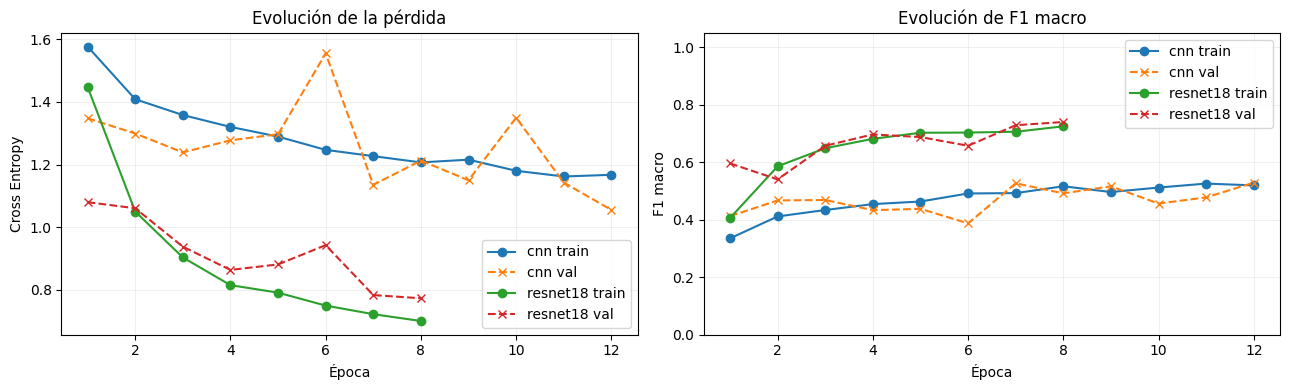

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for nombre, h in historiales.items():
    axes[0].plot(h['epoca'], h['train_loss'], marker='o', label=f'{nombre} train')
    axes[0].plot(h['epoca'], h['val_loss'], marker='x', linestyle='--', label=f'{nombre} val')
    axes[1].plot(h['epoca'], h['train_f1'], marker='o', label=f'{nombre} train')
    axes[1].plot(h['epoca'], h['val_f1'], marker='x', linestyle='--', label=f'{nombre} val')
axes[0].set(title='Evolución de la pérdida', xlabel='Época', ylabel='Cross Entropy')
axes[1].set(title='Evolución de F1 macro', xlabel='Época', ylabel='F1 macro', ylim=(0, 1.05))
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(ARTIFACTS / 'curvas_aprendizaje.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Evaluación final en datos de prueba

Ambos modelos se evalúan una sola vez en test, **después** de elegir el ganador con validación. Estas son las métricas que se deben poner en la presentación; no deben copiarse resultados de otros proyectos.

  modelo  f1_validacion  accuracy_test  precision_macro_test  recall_macro_test  f1_macro_test
resnet18         0.7399         0.7863                0.7691             0.7578         0.7616
     cnn         0.5289         0.5620                0.5751             0.5859         0.5363

REPORTE DEL MODELO ELEGIDO: resnet18
              precision  recall  f1-score  support
cardboard         0.931   0.900     0.915   60.000
glass             0.671   0.671     0.671   76.000
metal             0.762   0.787     0.774   61.000
paper             0.925   0.831     0.876   89.000
plastic           0.714   0.833     0.769   72.000
trash             0.611   0.524     0.564   21.000
accuracy          0.786   0.786     0.786    0.786
macro avg         0.769   0.758     0.762  379.000
weighted avg      0.791   0.786     0.787  379.000


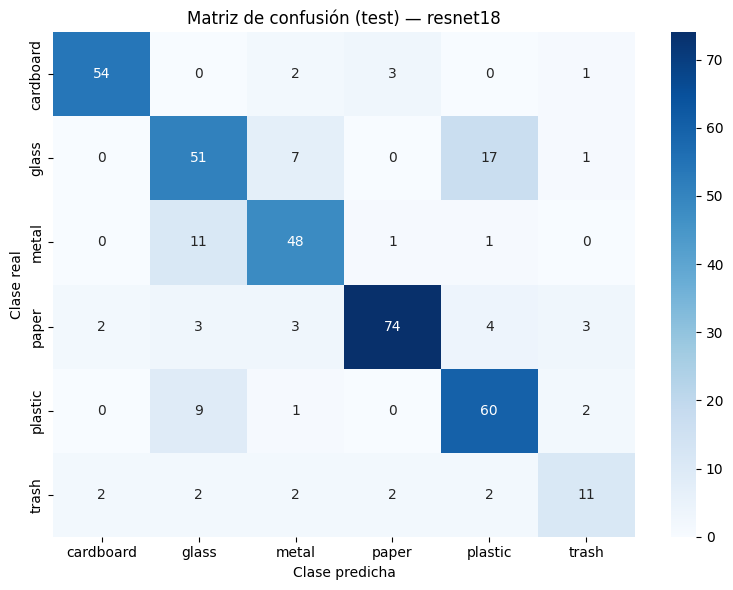

In [20]:
res_test = {nombre: evaluar(m, test_dl, criterio) for nombre, m in modelos_entrenados.items()}
comparacion = pd.DataFrame([{
    'modelo': nombre,
    'f1_validacion': f1_val[nombre],
    'accuracy_test': res['accuracy'],
    'precision_macro_test': precision_score(res['y_real'], res['y_pred'], average='macro', zero_division=0),
    'recall_macro_test': recall_score(res['y_real'], res['y_pred'], average='macro', zero_division=0),
    'f1_macro_test': res['f1_macro'],
} for nombre, res in res_test.items()]).sort_values('f1_validacion', ascending=False)
print(comparacion.to_string(index=False, float_format=lambda v: f'{v:.4f}'))
comparacion.to_csv(ARTIFACTS / 'comparacion_modelos.csv', index=False)

final = res_test[mejor_nombre]
print('\nREPORTE DEL MODELO ELEGIDO:', mejor_nombre)
reporte = classification_report(final['y_real'], final['y_pred'], labels=list(range(len(clases))),
                                target_names=clases, zero_division=0, output_dict=True)
print(pd.DataFrame(reporte).T.round(3).to_string())
pd.DataFrame(reporte).T.to_csv(ARTIFACTS / 'reporte_por_clase.csv')

cm = confusion_matrix(final['y_real'], final['y_pred'], labels=list(range(len(clases))))
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=clases, yticklabels=clases)
plt.xlabel('Clase predicha')
plt.ylabel('Clase real')
plt.title(f'Matriz de confusión (test) — {mejor_nombre}')
plt.tight_layout()
plt.savefig(ARTIFACTS / 'matriz_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Análisis de errores y ejemplos reales

Se muestran predicciones incorrectas de la partición test. Este análisis ayuda a identificar clases difíciles y posibles efectos de iluminación, fondo o similitud de materiales. Una clasificación correcta en este dataset **no garantiza** el rendimiento en fotografías tomadas en otros entornos.

Errores en test: 81 de 379


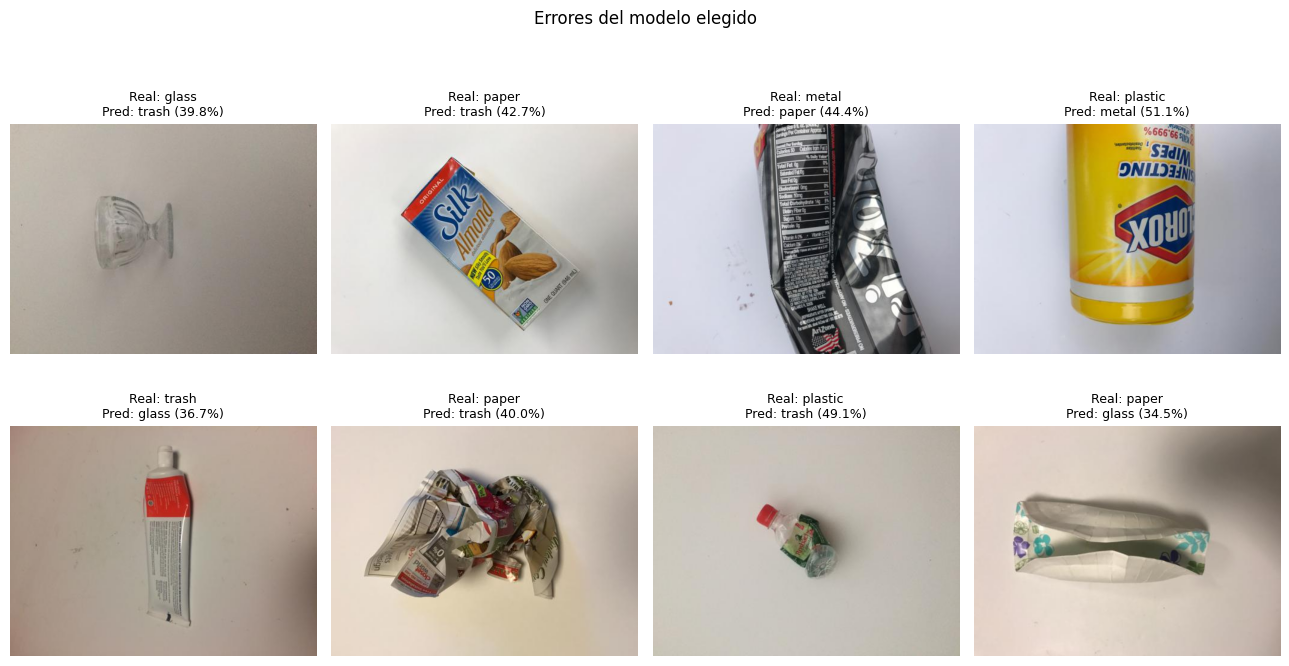

In [21]:
indices_error = np.flatnonzero(np.array(final['y_real']) != np.array(final['y_pred']))
print('Errores en test:', len(indices_error), 'de', len(test_df))
if len(indices_error):
    seleccion = indices_error[:min(8, len(indices_error))]
    fig, axes = plt.subplots(2, 4, figsize=(13, 7))
    for ax, i in zip(axes.flat, seleccion):
        with Image.open(test_df.loc[int(i), 'ruta']) as imagen:
            ax.imshow(imagen.convert('RGB'))
        real = clases[final['y_real'][i]]
        predicho = clases[final['y_pred'][i]]
        confianza = final['probas'][i].max()
        ax.set_title(f'Real: {real}\nPred: {predicho} ({confianza:.1%})', fontsize=9)
        ax.axis('off')
    for ax in axes.flat[len(seleccion):]:
        ax.axis('off')
    plt.suptitle('Errores del modelo elegido', y=1.02)
    plt.tight_layout()
    plt.savefig(ARTIFACTS / 'ejemplos_errores.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('No hubo errores en esta muestra; revisar datos, separación y generalización externa.')

## 7. Interpretabilidad visual: Grad-CAM

El mapa superpuesto destaca regiones que contribuyen a la clase predicha. Es **una visualización explicativa aproximada**, no una prueba causal de por qué el modelo decidió algo. Se calcula sobre una imagen de prueba, sin reentrenar.

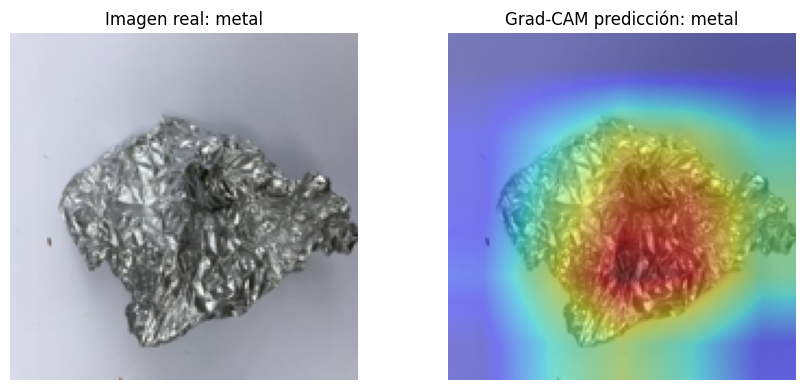

In [22]:
import torch.nn.functional as F

def calcular_gradcam(modelo, x, layer):
    activaciones = []
    gradientes = []
    def guardar_activacion(mod, entrada, salida):
        activaciones.append(salida.detach())
        salida.register_hook(lambda grad: gradientes.append(grad.detach()))
    handle = layer.register_forward_hook(guardar_activacion)
    modelo.eval()
    try:
        with torch.enable_grad():
            modelo.zero_grad(set_to_none=True)
            logits = modelo(x.clone().detach().requires_grad_(True))
            cls = int(logits.argmax(dim=1).item())
            logits[0, cls].backward()
        a = activaciones[0]
        g = gradientes[0]
        pesos = g.mean(dim=(2, 3), keepdim=True)
        heatmap = torch.relu((pesos * a).sum(dim=1, keepdim=True))
        heatmap = F.interpolate(heatmap, size=(IMAGE_SIZE, IMAGE_SIZE), mode='bilinear', align_corners=False)
        heatmap = heatmap[0, 0].cpu().numpy()
        heatmap = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min() + 1e-8)
    finally:
        handle.remove()
    return heatmap, cls

idx_ejemplo = 0
x, y = ResiduosDataset(test_df, val_tfms)[idx_ejemplo]
layer = (mejor_modelo.layer4[-1] if mejor_nombre == 'resnet18'
         else mejor_modelo.features[8])
heat, pred = calcular_gradcam(mejor_modelo, x.unsqueeze(0).to(device), layer)
with Image.open(test_df.loc[idx_ejemplo, 'ruta']) as im:
    imagen_original = im.convert('RGB').resize((IMAGE_SIZE, IMAGE_SIZE))
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(imagen_original)
axes[0].set_title(f'Imagen real: {clases[y]}')
axes[1].imshow(imagen_original)
axes[1].imshow(heat, cmap='jet', alpha=0.45, vmin=0, vmax=1)
axes[1].set_title(f'Grad-CAM predicción: {clases[pred]}')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.savefig(ARTIFACTS / 'gradcam.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Exportar el modelo y las métricas

El archivo `artifacts/best_model.pth` se utiliza en `app.py`. Los gráficos y resultados CSV se guardan en la misma carpeta, para usarlos en las diapositivas. La aplicación **no funcionará** hasta generar este archivo ejecutando el notebook.

In [23]:
checkpoint = {
    'architecture': mejor_nombre,
    'model_state_dict': {k: v.detach().cpu() for k, v in mejor_modelo.state_dict().items()},
    'classes': clases,
    'image_size': IMAGE_SIZE,
    'mean': MEAN,
    'std': STD,
    'seed': SEED,
    'modo_rapido': MODO_RAPIDO,
}
torch.save(checkpoint, ARTIFACTS / 'best_model.pth')
metricas = {
    'dataset': DATASET_ID,
    'n_train': len(train_df), 'n_val': len(val_df), 'n_test': len(test_df),
    'classes': clases,
    'modo_rapido': MODO_RAPIDO,
    'mejor_modelo_segun_validacion': mejor_nombre,
    'f1_val': f1_val,
    'metricas_test': comparacion.to_dict(orient='records'),
}
(ARTIFACTS / 'metricas.json').write_text(json.dumps(metricas, indent=2, ensure_ascii=False), encoding='utf-8')
for nombre, hist in historiales.items():
    hist.to_csv(ARTIFACTS / f'historial_{nombre}.csv', index=False)
print('Archivos exportados a:', ARTIFACTS.resolve())
print('Modelo:', ARTIFACTS / 'best_model.pth')

Archivos exportados a: /content/artifacts
Modelo: artifacts/best_model.pth


## 9. Conclusiones del entrenamiento completo

**Configuración evaluada.** El entrenamiento se ejecutó con `MODO_RAPIDO = False` sobre CPU. Se utilizaron **2.524 imágenes válidas** (tras descartar 3 archivos duplicados exactos), divididas en **1.766 entrenamiento**, **379 validación** y **379 prueba**, con seis categorías: cardboard, glass, metal, paper, plastic y trash. La selección del modelo se hizo **por F1 macro en validación** antes de evaluar en test.

**Comparación final sobre test.** La CNN entrenada desde cero obtuvo accuracy **56,20 %** y F1 macro **53,63 %**. ResNet18 con pesos de ImageNet y extractor congelado obtuvo accuracy **78,63 %**, precision macro **76,91 %**, recall macro **75,78 %** y F1 macro **76,16 %**. Esto supone una diferencia favorable a ResNet18 de **22,43 puntos porcentuales** de accuracy y **22,53 puntos** de F1 macro. En test clasificó correctamente **298 de 379** imágenes.

**Hallazgos por categoría.** Cartón mostró F1 **91,53 %** y papel F1 **87,57 %**, mientras que basura general obtuvo F1 **56,41 %** y recall **52,38 %**; esta última categoría tiene solo **137 imágenes** en todo el conjunto. La confusión notable incluye **17 imágenes de vidrio clasificadas como plástico**, **9 de plástico clasificadas como vidrio** y **11 de metal clasificadas como vidrio**.

**Interpretación.** La transferencia de aprendizaje con un extractor preentrenado resultó más eficaz que la pequeña CNN propia en este conjunto y configuración. Estos datos no permiten atribuir toda la diferencia únicamente al preentrenamiento, porque ambas arquitecturas tienen distinta capacidad. Grad-CAM visualiza regiones influyentes en una predicción, pero no valida por sí mismo que la predicción sea correcta.

**Limitaciones y siguiente paso.** Los resultados proceden de **una sola partición estratificada** de un dataset limitado; el control de duplicados detecta coincidencias exactas, no imágenes casi idénticas. No se ha medido rendimiento con fotografías externas, iluminación variable, múltiples objetos ni residuos mezclados. La confianza *softmax* no está calibrada. **El despliegue de Streamlit sigue pendiente de validación real**; no debe afirmarse que la aplicación ya está publicada. El objetivo inmediato es comprobar el archivo `artifacts/best_model.pth` en la aplicación y hacer pruebas con imágenes nuevas.


In [24]:
from google.colab import files
import shutil

shutil.make_archive(
    "EcoVision_Resultados",
    "zip",
    "artifacts"
)

files.download("EcoVision_Resultados.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>